# Unwrapped interferograms (dolphin)

Plots all `*.unw.tif` files from a dolphin `unwrapped/` folder as a grid of thumbnails (several pages if there are many).

* Phase is in radians; nodata (`0`) is masked.
* Optional: mask pixels with connected component `0` (unreliable unwrapping) using the matching `*.unw.conncomp.tif`.
* Optional: reference each interferogram to its spatial median so the maps are comparable.
* Rasters are decimated on read (`DOWNSAMPLE`) to keep it fast.

In [1]:
from pathlib import Path
from datetime import datetime

import numpy as np
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

## Settings

In [2]:
UNW_DIR = Path("/home/lukas/projects/ADUCAT/data/sweets_fork_test2/dolphin/unwrapped")

NCOLS = 6               # thumbnails per row
PER_PAGE = 36           # interferograms per figure
DOWNSAMPLE = 2          # read every n-th pixel (1 = full resolution)
MASK_CONNCOMP0 = True   # mask pixels with conncomp == 0
REF_MEDIAN = True       # subtract spatial median from each interferogram
CLIM = None             # fixed colour limit in rad (e.g. 10); None = 98th percentile per ifg
MAX_TEMP_BASELINE = None  # only plot pairs with temporal baseline <= N days; None = all
SAVE_DIR = None         # e.g. UNW_DIR.parent / "unw_plots" to save PNGs

## Collect files

In [3]:
def pair_dates(path):
    d1, d2 = path.name.split(".")[0].split("_")
    return datetime.strptime(d1, "%Y%m%d"), datetime.strptime(d2, "%Y%m%d")


unw_files = sorted(UNW_DIR.glob("*.unw.tif"))
if MAX_TEMP_BASELINE is not None:
    unw_files = [f for f in unw_files if (pair_dates(f)[1] - pair_dates(f)[0]).days <= MAX_TEMP_BASELINE]

btemps = [(d2 - d1).days for d1, d2 in map(pair_dates, unw_files)]
print(f"{len(unw_files)} unwrapped interferograms in {UNW_DIR}")
if unw_files:
    print(f"Date range:         {pair_dates(unw_files[0])[0]:%Y-%m-%d} .. {max(pair_dates(f)[1] for f in unw_files):%Y-%m-%d}")
    print(f"Temporal baselines: {sorted(set(btemps))} days")
    with rasterio.open(unw_files[0]) as src:
        print(f"Size: {src.width} x {src.height} px, res {src.res}, CRS {src.crs}")

270 unwrapped interferograms in /home/lukas/projects/ADUCAT/data/sweets_fork_test2/dolphin/unwrapped
Date range:         2022-01-01 .. 2024-12-28
Temporal baselines: [12, 24, 36] days
Size: 1022 x 786 px, res (30.0, 30.0), CRS EPSG:32633


## Read + plot

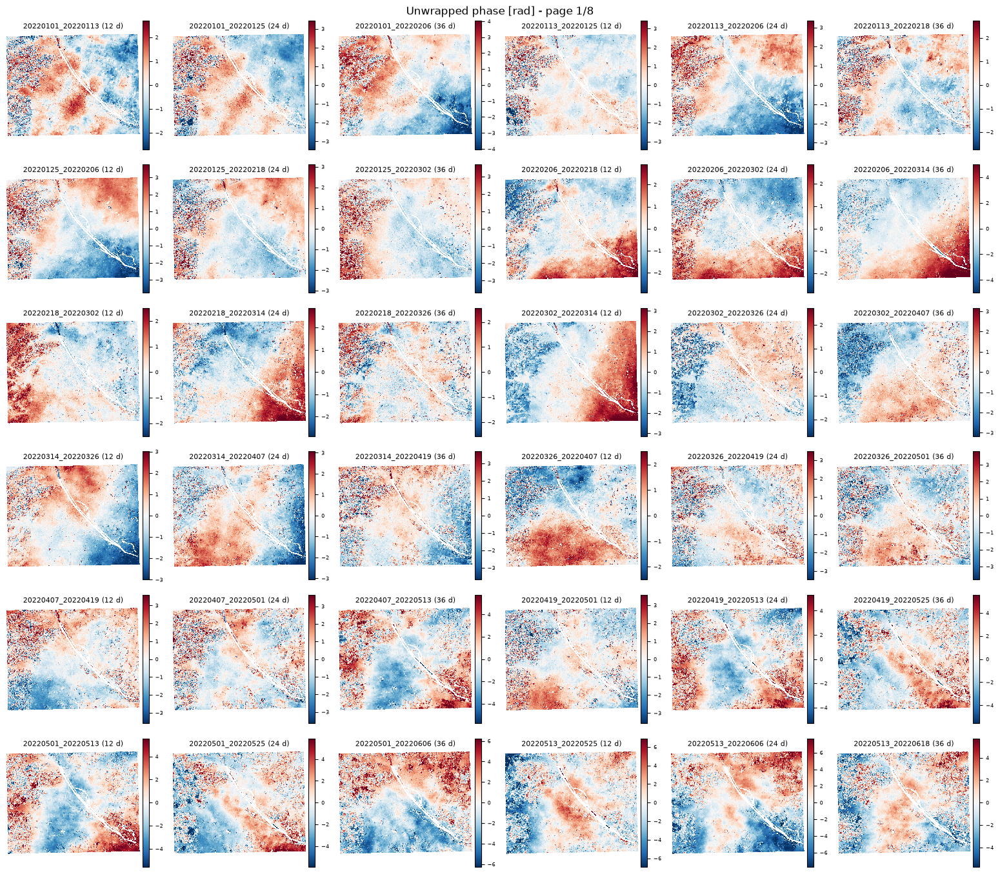

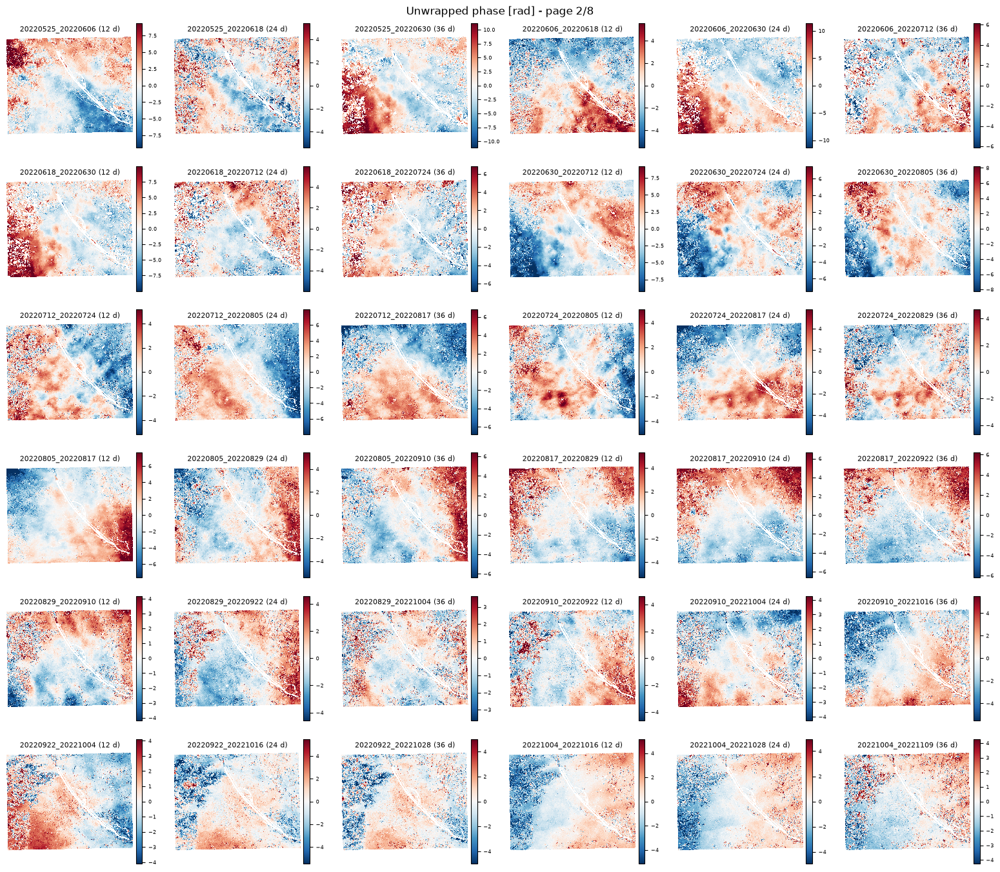

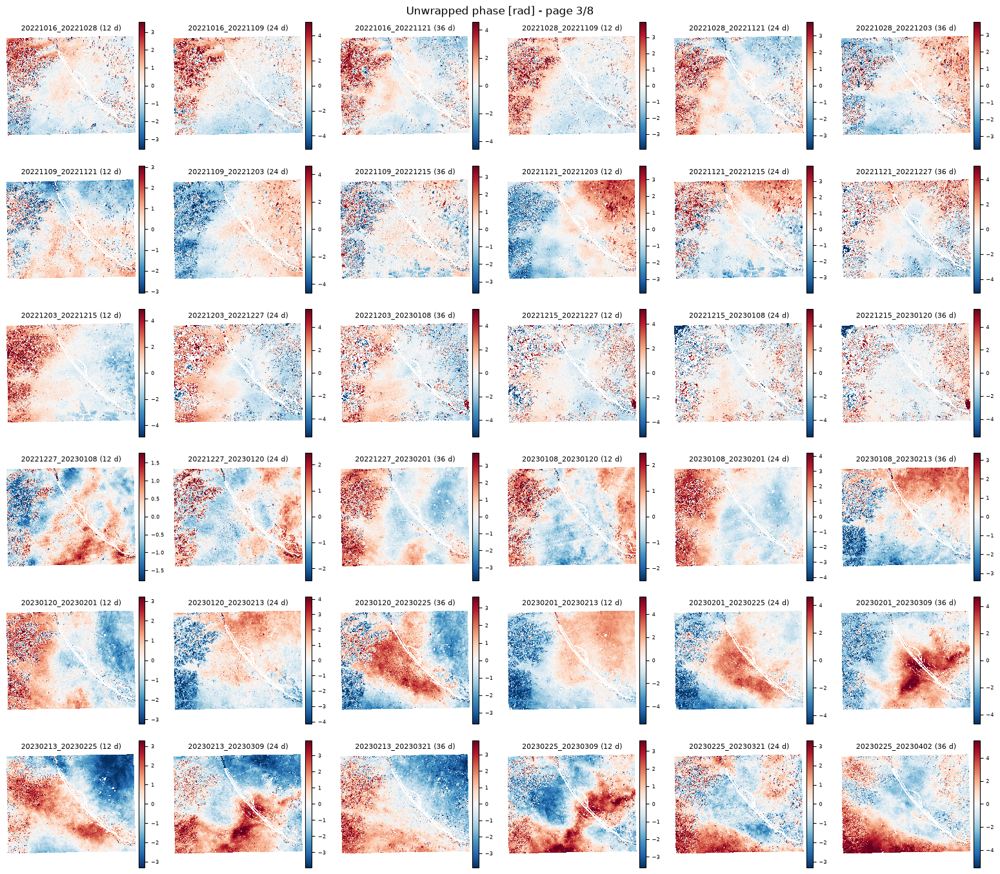

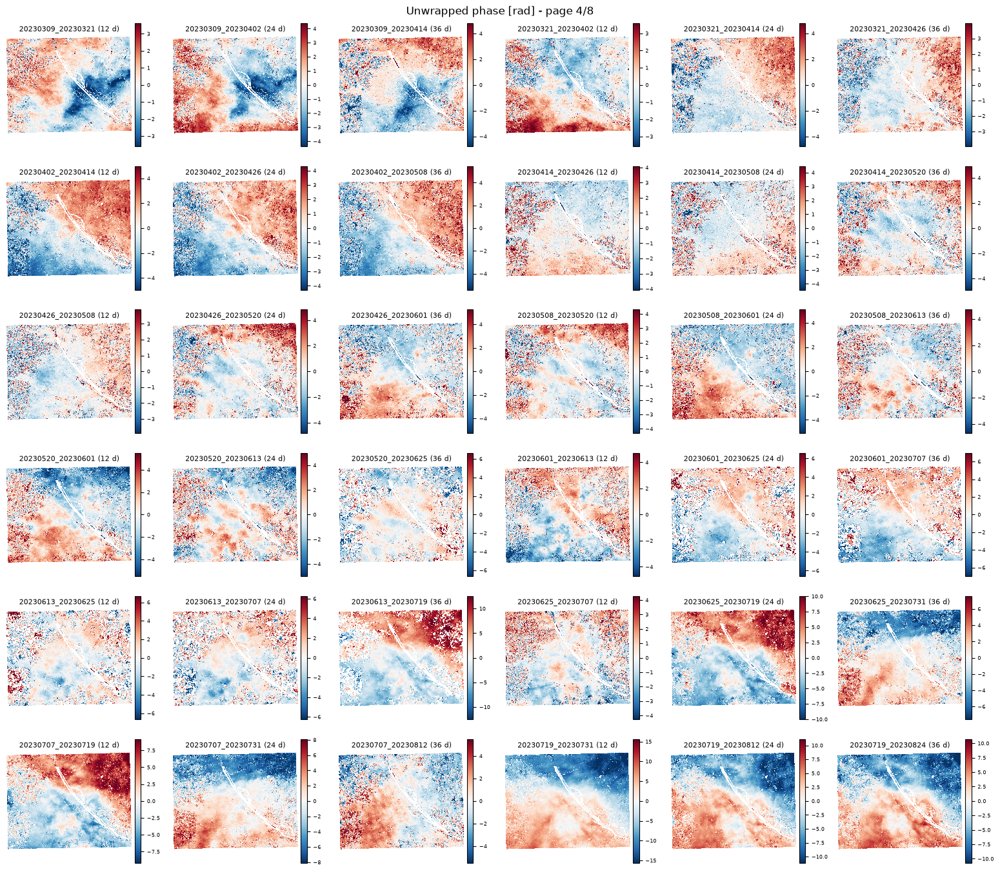

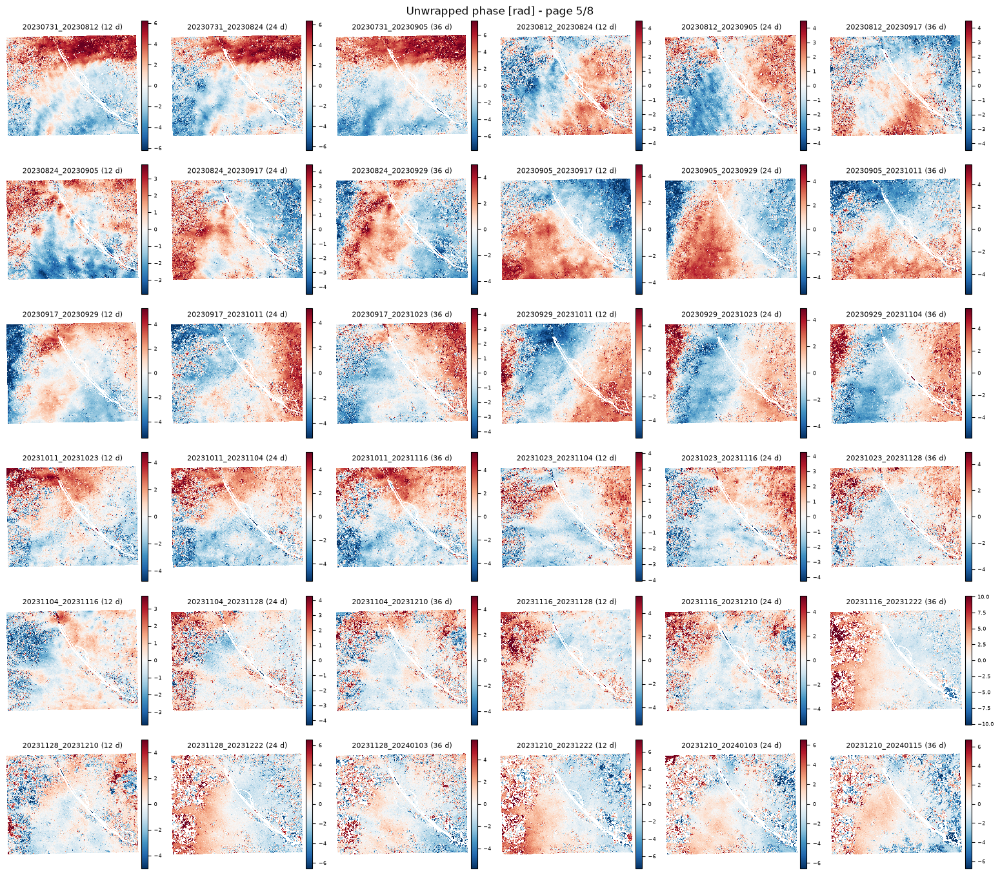

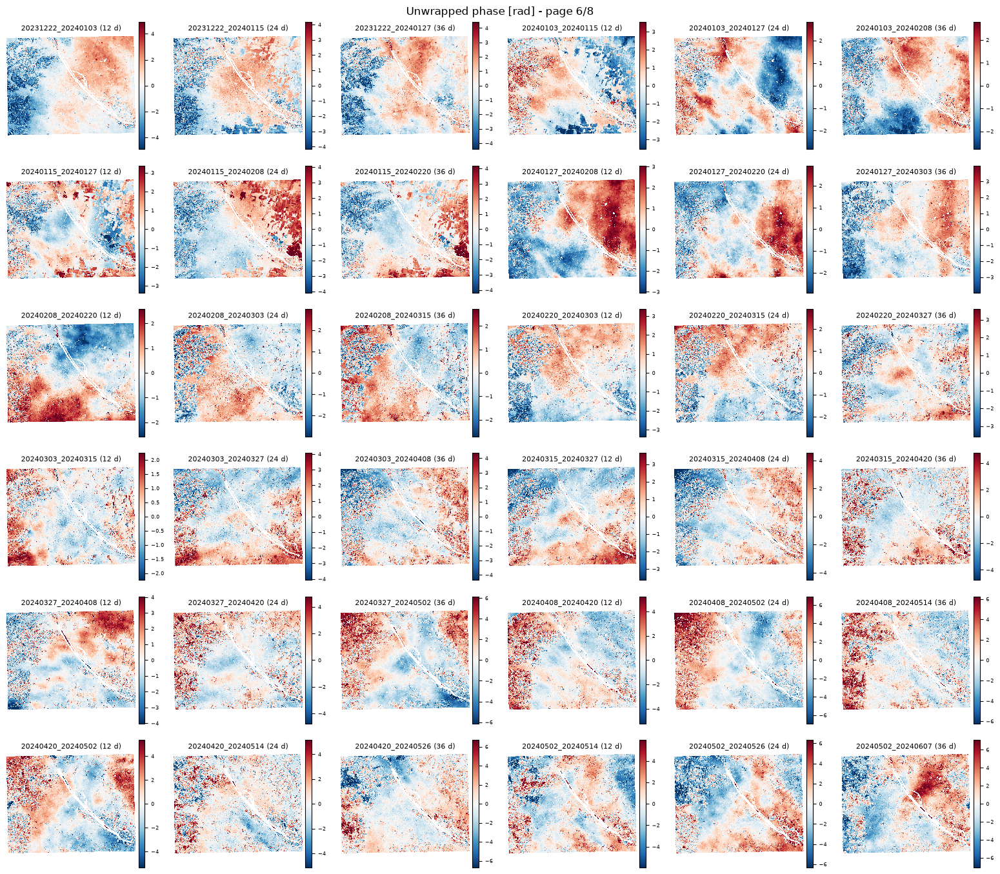

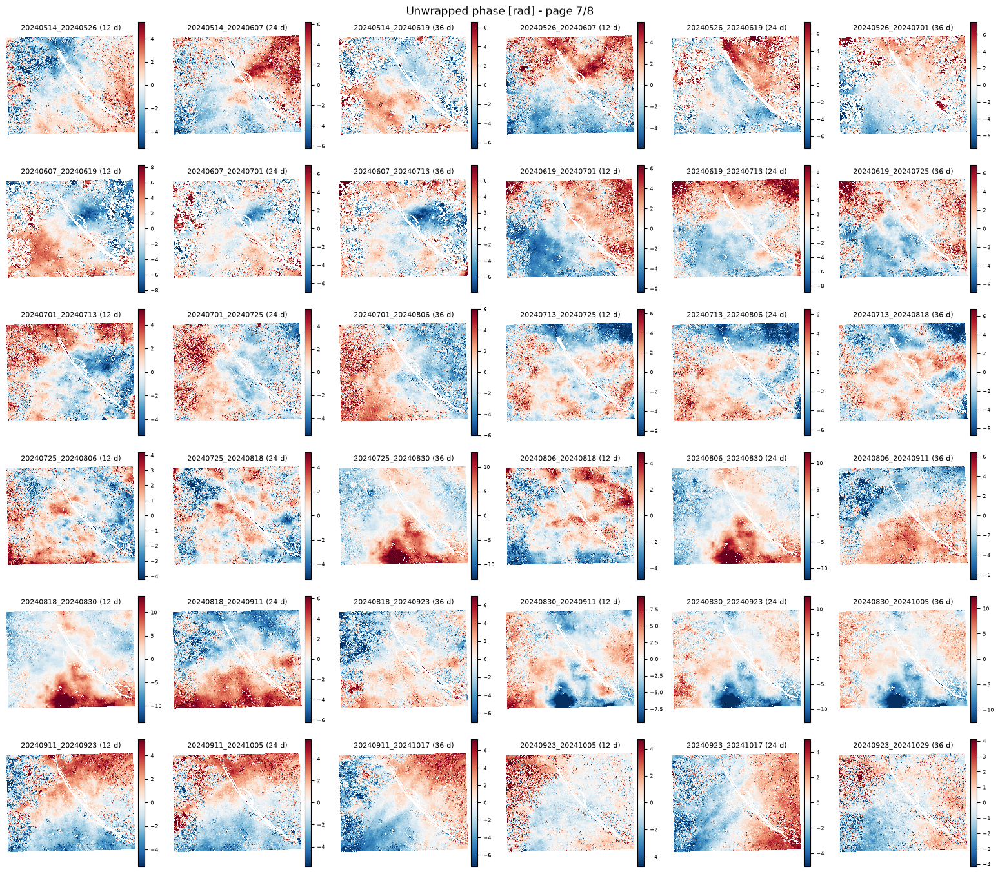

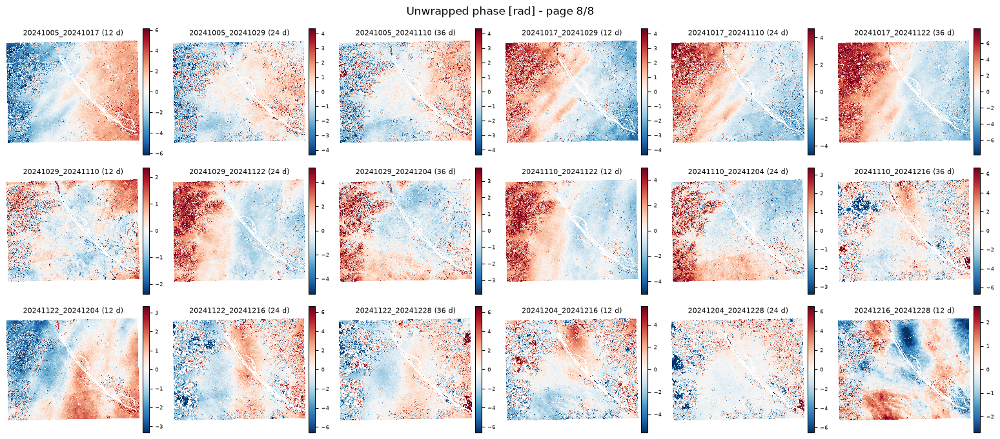

In [4]:
def read_unw(path):
    with rasterio.open(path) as src:
        shape = (src.height // DOWNSAMPLE, src.width // DOWNSAMPLE)
        unw = src.read(1, out_shape=shape, resampling=Resampling.nearest, masked=True).astype("float32")
        unw = unw.filled(np.nan)
        unw[unw == 0] = np.nan

    cc_file = path.with_name(path.name.replace(".unw.tif", ".unw.conncomp.tif"))
    if MASK_CONNCOMP0 and cc_file.exists():
        with rasterio.open(cc_file) as src:
            cc = src.read(1, out_shape=shape, resampling=Resampling.nearest)
        unw[(cc == 0) | (cc == src.nodata)] = np.nan

    if REF_MEDIAN and np.isfinite(unw).any():
        unw -= np.nanmedian(unw)
    return unw


def plot_page(files, page, n_pages):
    nrows = int(np.ceil(len(files) / NCOLS))
    fig, axes = plt.subplots(nrows, NCOLS, figsize=(2.6 * NCOLS, 2.3 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.set_axis_off()

    for ax, f in zip(axes.flat, files):
        unw = read_unw(f)
        if not np.isfinite(unw).any():
            ax.set_title(f"{f.name.split('.')[0]}\n(empty)", fontsize=8)
            continue
        vmax = CLIM if CLIM is not None else np.nanpercentile(np.abs(unw), 98)
        im = ax.imshow(unw, cmap="RdBu_r", vmin=-vmax, vmax=vmax, interpolation="nearest")
        d1, d2 = pair_dates(f)
        ax.set_title(f"{d1:%Y%m%d}_{d2:%Y%m%d} ({(d2 - d1).days} d)", fontsize=8)
        cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
        cb.ax.tick_params(labelsize=6)

    fig.suptitle(f"Unwrapped phase [rad] - page {page}/{n_pages}", fontsize=12)
    fig.tight_layout()
    if SAVE_DIR is not None:
        Path(SAVE_DIR).mkdir(parents=True, exist_ok=True)
        fig.savefig(Path(SAVE_DIR) / f"unw_page_{page:02d}.png", dpi=150)
    plt.show()


n_pages = int(np.ceil(len(unw_files) / PER_PAGE))
for i in range(n_pages):
    plot_page(unw_files[i * PER_PAGE:(i + 1) * PER_PAGE], i + 1, n_pages)

## Single interferogram (full resolution)

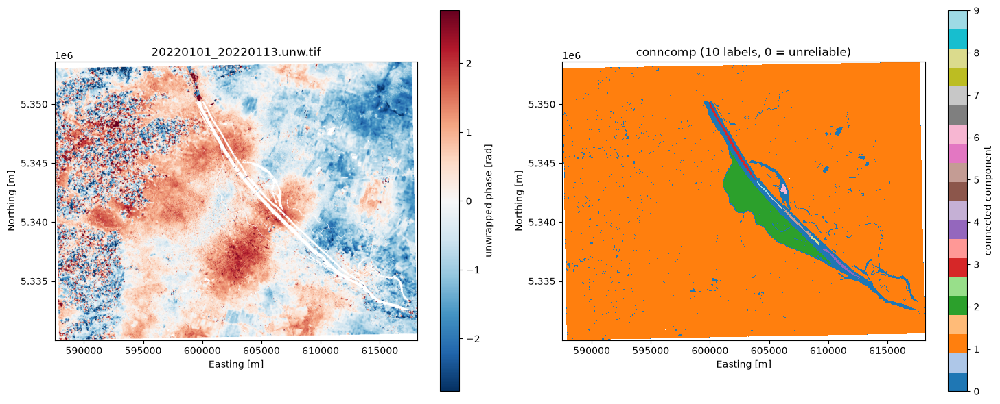

In [5]:
IFG = unw_files[0]  # pick any, e.g. UNW_DIR / "20250109_20250121.unw.tif"

with rasterio.open(IFG) as src:
    unw = src.read(1).astype("float32")
    extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]
unw[unw == 0] = np.nan
with rasterio.open(IFG.with_name(IFG.name.replace(".unw.tif", ".unw.conncomp.tif"))) as src:
    cc = src.read(1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
vmax = np.nanpercentile(np.abs(unw - np.nanmedian(unw)), 98)
im = ax1.imshow(unw - np.nanmedian(unw), cmap="RdBu_r", vmin=-vmax, vmax=vmax, extent=extent)
fig.colorbar(im, ax=ax1, label="unwrapped phase [rad]")
ax1.set_title(IFG.name)

cc_plot = np.ma.masked_equal(cc, 65535)
im = ax2.imshow(cc_plot, cmap="tab20", interpolation="nearest", extent=extent)
fig.colorbar(im, ax=ax2, label="connected component")
ax2.set_title(f"conncomp ({len(np.unique(cc_plot.compressed()))} labels, 0 = unreliable)")
for ax in (ax1, ax2):
    ax.set_xlabel("Easting [m]"); ax.set_ylabel("Northing [m]")
fig.tight_layout()
plt.show()